# MA385 Numerical Analysis - Explicit Methods
The first two sections of the course, covering explicit methods, which are apporximate and iterative, and are used to solve ODEs.

In [1]:
import numpy as np
from scipy.optimize import root_scalar
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Math, Latex
import sympy as sp
import math
from contextlib import contextmanager

#### Functions
Do not define f(x) as a global function, it is a variable within the method functions.  
  
$f_1(x) = x^2+3$ &emsp;&emsp; Note: does not cross x axis  
$f_2(x) = x^2=2$  
$f_3(x) = e^x-2x-2$  
$f_4(x) = e^x$  
$f_5(x) = \sin(x)$  
$f_6(x) = \cos(x)$

  
#### Note:  
$x\in[a,b]\implies a\leq x\leq b$ &emsp;&emsp; a ***closed*** interval ***includes*** its endpoints  
$x\in(a,b)\implies a < x < b$ &emsp;&emsp; an ***open*** interval ***excludes*** its endpoints  
So $(a,b) \in [a,b]$ but $[a,b] \notin (a,b)$


## Section 1: Solving Nonlinear Equations
Two-step methods: need $x_k$ _and_ $x_{k-1}$ to get $x_{k+1}$  
* Bisection
* Secant
  
Single-step methods: only need $x_k$ to get $x_{k+1}$
* Newton
* FPI
### 1.1 Root-Finding
#### Theorem 1.1.1
For a real-valued function $f$, continuous on bounded closed interval $[a, b] \in \reals$:  
&emsp; if $f(a)f(b)<0$,  
&emsp; then there exsits $\tau \in [a,b]$  
&emsp; such that $f(\tau)=0$  
  
Construct a series of estimates ${x_0, x_1, x_2,..., x_k}$ that converge on the true solution $\tau$  
Then show that $\lim_{k\to\infty} x_k = \tau$  
  
Let $\varepsilon_k$ be the bound on the error at step k:  $|\tau - x_k|<\varepsilon_k$>  
And because the method converges, the bound on the error is always decreasing: $|\tau-x_k|<|\tau-x_{k-1}|$    
Then: $\varepsilon_{k+1}<\mu\varepsilon_k$ for some number $\mu\epsilon(0,1)$

#### Exercise 1.1.1
Does Theorem 1.1 mean that, if there is a solution to $f(x) = 0$ in $[a, b]$ then $f(a)f(b) \leq 0$? That is, is $f(a)f(b) \leq 0$ a necessary condition for there being a solution to $f(x) = 0$? Give an example that supports your answer.  
  
Meetng the condition implies there is a solution, does the existence of a solution imply meeting the condition? $A \implies B$, does $B \implies A$?  
Answer: no

In [3]:
def f1(x):
    return x**2 + 3

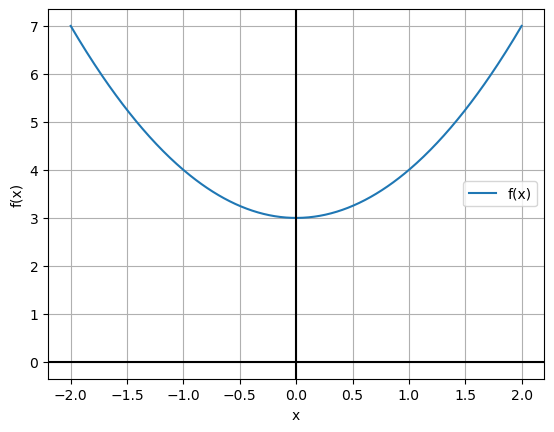

In [4]:
x = np.linspace(-2, 2, 401)  # 401 points between 0 and 3
plt.plot(x, f1(x))
plt.legend(['f(x)', '$\\tau$'])
plt.axhline(0, color='k', linewidth=1.5)  # x-axis
plt.axvline(0, color='k', linewidth=1.5)  # y-axis
plt.xlabel("x"), plt.ylabel("f(x)")
plt.grid(True)

This funciton breaks the condition: for $f(x)$ in $[-2, 2]$, $f(a)f(b)>0$, i.e. $f(a)f(b)$ have the same sign.  
Just becuase they are on teh same side of the axis, doesn;t meant he funciton can't cross it, just means it has to cross back.  
If there is _only_ one $\tau$, then the condition is necessary; if there are multiple $\tau$ then it's not.

### 1.2 Interval Bisection
a.k.a. "The Bisection Method".  
For a function satisfying the conditions of Theorem 1.1.1:  
* Set $x_2$ to be the midpoint of interval $[x_0, x_2]$
* Choose whichever sub-interval $[x_0, x_2]$ or $[x_2, x_1]$ where $f$ changes sign
* Repeat on sub-intervals
  
Because we are reducing the solution space by a factor of 2 with every step k (i.e. scale by $(\frac{1}{2})^k$), then as $k \to \infty$, solution space $2^{-k}\to0 \implies$ convergence.

In [5]:
def bisection(f, a, b, eps=10**(-10), K=None):
    true_soln = root_scalar(f, bracket=[a, b], xtol=1e-15).root
    x_k_all = [a, b]
    if K != None:
        eps = 10**(-30)
    if abs(f(a)) <= eps:
        x_k_all = [a]
    elif abs(f(b)) <= eps:
        x_k_all = [a, b]
    else:
        x_L, x_R = a, b
        k = 2
        cont = True
        while cont:
            x_k = (x_L + x_R)/2
            x_k_all.append(x_k)
            if f(x_L)*f(x_k) < 0:
                x_R = x_k
            else:
                x_L = x_k
            if abs(f(x_k)) <= eps:
                cont = False
            else:
                k += 1
                if K != None and k >= K:
                    cont = False

    x = np.linspace(a, b, 401)
    plt.plot(x, f(x))
    plt.plot(x_k_all, [0]*(len(x_k_all)), "^", color = "gray")
    plt.plot(true_soln, [0], "^", color = "r")
    plt.legend(['f(x)', '$x_k$','$\\tau$'])
    plt.axhline(0, color='k', linewidth=1.5)  # x-axis
    plt.axvline(0, color='k', linewidth=1.5)  # y-axis
    plt.xlabel("x"), plt.ylabel("f(x)")
    plt.xlim(a,b)
    plt.grid(True)
    plt.show()

    k_all = range(k+2)
    fxk_all = [abs(f(xk)) for xk in x_k_all]
    err_bound = [abs(true_soln - xk) for xk in x_k_all]
    display(Latex(rf"$\tau = {true_soln:.6f}$"))

    df = pd.DataFrame(zip(k_all, x_k_all, fxk_all, err_bound), columns = ["k", "x_k", "|f(x_k)|", "|tau - x_k|"])
    print(df.to_string(index = False))

In [6]:
def f2(x):
    return x**2 - 2

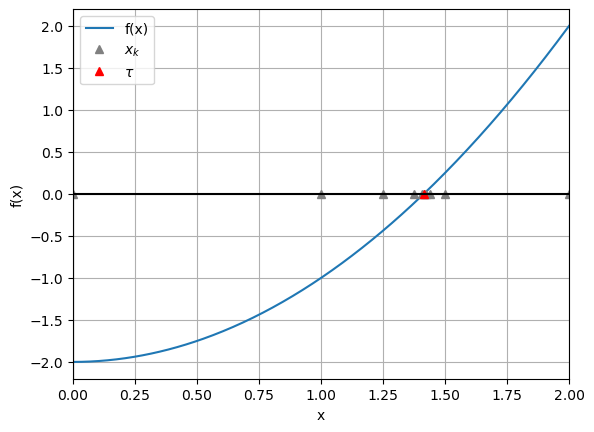

<IPython.core.display.Latex object>

 k      x_k  |f(x_k)|  |tau - x_k|
 0 0.000000  2.000000     1.414214
 1 2.000000  2.000000     0.585786
 2 1.000000  1.000000     0.414214
 3 1.500000  0.250000     0.085786
 4 1.250000  0.437500     0.164214
 5 1.375000  0.109375     0.039214
 6 1.437500  0.066406     0.023286
 7 1.406250  0.022461     0.007964
 8 1.421875  0.021729     0.007661
 9 1.414062  0.000427     0.000151


In [7]:
bisection(f2, 0, 2, 0.001)

#### Theorem 1.2.1
Let $x_k$ be the $k$th iteration generated by the Bisection Method. Then:
$$ |\tau = x_0| \leq (\frac{1}{2})^{k-1}|b-a| \text{ , for } k = 2, 3, 4, ... $$

#### Exercise 1.2.3
Let f (x) = e^x − 2x − 2. Show that there is a solution to the
problem: find τ ∈ [0, 2] such that f (τ ) = 0.
Taking x0 = 0 and x1 = 2, use 6 steps of the bisection method
to estimate τ . You may use a computer program to do this,
but please note that in your solution.
Give an upper bound for the error |τ − x6|.

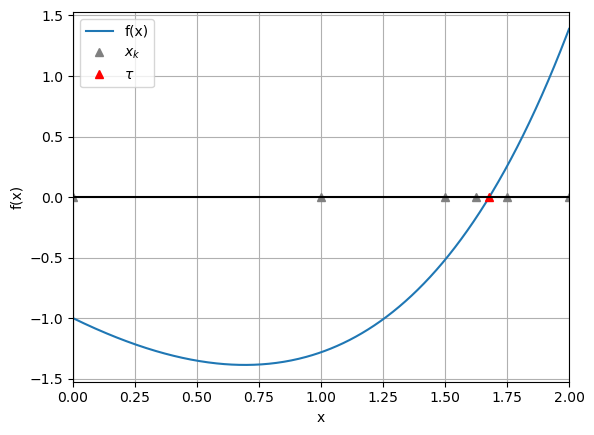

<IPython.core.display.Latex object>

 k   x_k  |f(x_k)|  |tau - x_k|
 0 0.000  1.000000     1.678347
 1 2.000  1.389056     0.321653
 2 1.000  1.281718     0.678347
 3 1.500  0.518311     0.178347
 4 1.750  0.254603     0.071653
 5 1.625  0.171581     0.053347


In [8]:
def f3(x):
    return np.exp(x)-2*x-2
bisection(f3, 0, 2, K=6)

### 1.3 The Secant Method
Instead of bisecting the separation between $x_0$ and $x_1$, take $x_2$ to be the zero of the line joining the points $(x_0, f(x_0)), (x_1,f(x_1))$; then take $x_3$ to be the zero of the line joining the points $(x_1, f(x_1)), (x_2,f(x_2))$
  
Formally: choose $x_0, x_1$ sucht that there is a solution in $[x_0,x_1]$, then define:
$$ x_{k+1} = x_k-f(x_k)\frac{x_k-x_{k-1}}{f(x_k)-f(x_{k-1})} \text{ , for }k = 1,2,3,..$$

In [9]:
def secant(f, a, b, eps=10**(-10), K=None):
    true_soln = root_scalar(f, bracket=[a, b], xtol=1e-15).root
    x_k_all = [a, b]
    if K != None:
        eps = 10**(-30)
    if abs(f(a)) <= eps:
        x_k_all = [a]
    elif abs(f(b)) <= eps:
        x_k_all = [a, b]
    else:
        x_k0, x_k1 = a, b
        k = 2
        cont = True
        while cont:
            x_k2 = x_k1 - f(x_k1)*(x_k1-x_k0)/(f(x_k1)-f(x_k0))
            x_k_all.append(x_k2)
            x_k0 = x_k1
            x_k1 = x_k2
            if abs(f(x_k2)) <= eps:
                cont = False
            else:
                k += 1
                if K != None and k >= K:
                    cont = False

    x = np.linspace(a, b, 401)
    plt.plot(x, f(x))
    plt.plot(x_k_all, [0]*(len(x_k_all)), "^", color = "gray")
    plt.plot(true_soln, [0], "^", color = "r")
    plt.legend(['f(x)', '$x_k$','$\\tau$'])
    for i in range(1,len(x_k_all)):
            xa, xb = x_k_all[i-1], x_k_all[i]
            fa, fb = f(xa), f(xb)
            xn = xb - fb * (xb - xa) / (fb - fa)
            plt.plot([xa, xb, xn], [fa, fb, 0], "--", color="gray", alpha = 0.8)
    plt.axhline(0, color='k', linewidth=1.5)  # x-axis
    plt.axvline(0, color='k', linewidth=1.5)  # y-axis
    plt.xlabel("x"), plt.ylabel("f(x)")
    plt.xlim(a,b)
    plt.grid(True)
    plt.show()

    k_all = range(k+2)
    fxk_all = [abs(f(xk)) for xk in x_k_all]
    err_bound = [abs(true_soln - xk) for xk in x_k_all]
    display(Latex(rf"$\tau = {true_soln:.6f}$"))

    df = pd.DataFrame(zip(k_all, x_k_all, fxk_all, err_bound), columns = ["k", "x_k", "|f(x_k)|", "|tau - x_k|"])
    print(df.to_string(index = False))

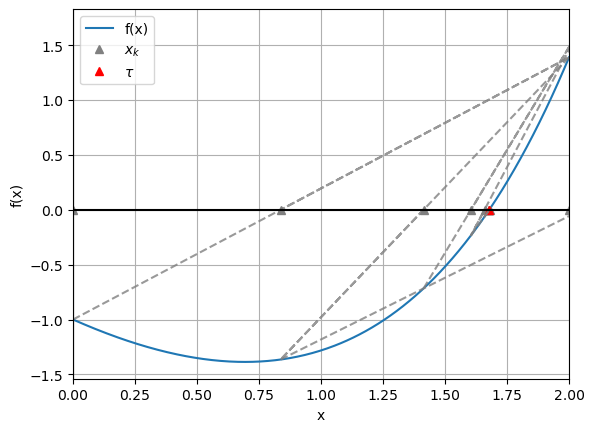

<IPython.core.display.Latex object>

 k      x_k     |f(x_k)|  |tau - x_k|
 0 0.000000 1.000000e+00 1.678347e+00
 1 2.000000 1.389056e+00 3.216530e-01
 2 0.837151 1.364525e+00 8.411963e-01
 3 1.413396 7.169040e-01 2.649514e-01
 4 2.051287 1.675334e+00 3.729405e-01
 5 1.604559 2.334545e-01 7.378845e-02
 6 1.659196 6.330870e-02 1.915122e-02
 7 1.679525 3.959476e-03 1.178468e-03
 8 1.678329 6.095516e-05 1.815955e-05
 9 1.678347 5.728692e-08 1.706647e-08
10 1.678347 8.295586e-13 2.471356e-13


In [10]:
secant(f3,0,2)

### 1.4 Taylor's Theorem
The __Taylor Polynomial__ of degree __k__ (aka _Truncated Taylor Series_) that approximates the function $f$ about the point $x=a$ is:
$$p_k(x)=f(a)+(x-a)f'(a)+\frac{(x-a)^2}{2}f''(a)+\frac{(x-a)^3}{3!}f'''(a)+...+\frac{(x-a)^k}{k!}f^{(k)}(a)$$

In [11]:
_RENAME = {"arcsin": "asin", "arccos": "acos", "arctan": "atan",
           "arcsinh": "asinh", "arccosh": "acosh", "arctanh": "atanh",
           "abs": "Abs", "absolute": "Abs"}
_NAMES = ["exp", "log", "sqrt", "sin", "cos", "tan", "sinh", "cosh", "tanh",
          "arcsin", "arccos", "arctan", "arcsinh", "arccosh", "arctanh", "abs"]

@contextmanager
def numpy_as_sympy():
    saved = {n: getattr(np, n) for n in _NAMES}
    try:
        for n in _NAMES:
            setattr(np, n, getattr(sp, _RENAME.get(n, n)))
        yield
    finally:
        for n, fn in saved.items():
            setattr(np, n, fn)

def to_sympy(f):
    "Return the SymPy expression for f(x), even if f uses np.* functions. For input to deriv funciton"
    x = sp.symbols("x")
    with numpy_as_sympy():
        return f(x)

def deriv(f, n=1):
    x = sp.symbols("x")
    return sp.lambdify(x, sp.diff(to_sympy(f), x, n))

In [12]:
def taylor(f, x, a, k):
    "Returns Taylor Polynomial of degree k for f(x) about x = a"
    p = f(a)
    for i in range(1,k+1):
        p = p + ((x-a)**i/math.factorial(i))*deriv(f, i)(a)
    return p

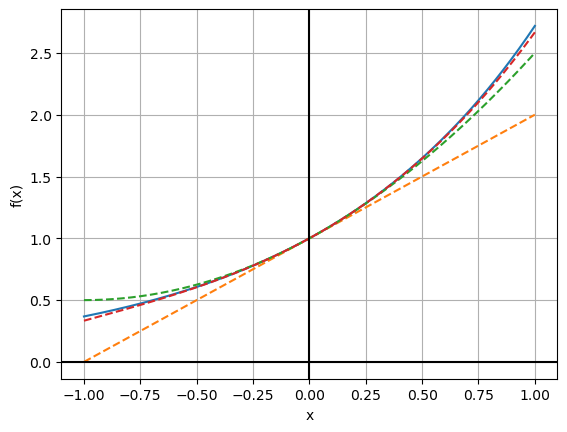

In [13]:
def f4(x):
    return np.exp(x)
f = f4
x = np.linspace(-1, 1, 401)
p1 = taylor(f, x, 0, 1)
plt.plot(x, f(x))
plt.plot(x, p1, "--")
plt.plot(x, taylor(f, x, 0, 2), "--")
plt.plot(x, taylor(f, x, 0, 3), "--")
#plt.plot(x, f(x)-p1, linestyle="dotted")
plt.axhline(0, color='k', linewidth=1.5)  # x-axis
plt.axvline(0, color='k', linewidth=1.5)  # y-axis
plt.xlabel("x"), plt.ylabel("f(x)")
plt.grid(True)
plt.show()

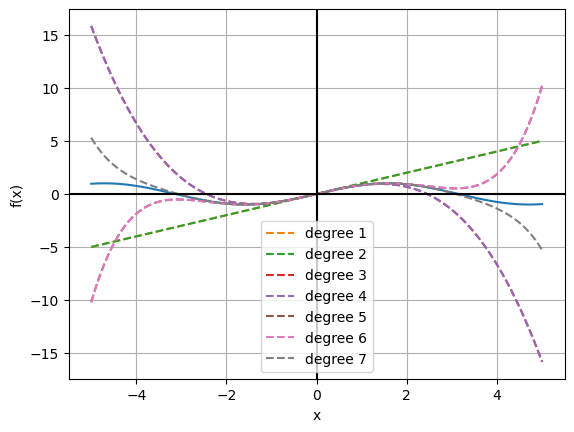

In [14]:
def f5(x):
    return np.sin(x)
f = f5
x = np.linspace(-5, 5, 401)
plt.plot(x, f(x))
for i in range(1,8):
    plt.plot(x, taylor(f, x, 0, i), "--", label = f"degree {i}")
#plt.plot(x, f(x)-p1, linestyle="dotted")
plt.axhline(0, color='k', linewidth=1.5)  # x-axis
plt.axvline(0, color='k', linewidth=1.5)  # y-axis
plt.legend()
plt.xlabel("x"), plt.ylabel("f(x)")
plt.grid(True)
plt.show()

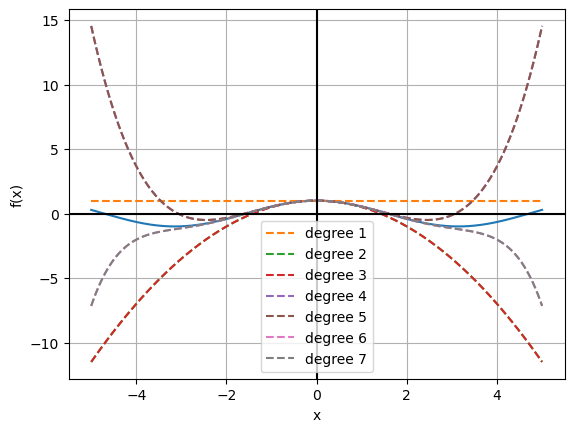

In [15]:
def f6(x):
    return np.cos(x)
f = f6
x = np.linspace(-5, 5, 401)
plt.plot(x, f(x))
for i in range(1,8):
    plt.plot(x, taylor(f, x, 0, i), "--", label = f"degree {i}")
#plt.plot(x, f(x)-p1, linestyle="dotted")
plt.axhline(0, color='k', linewidth=1.5)  # x-axis
plt.axvline(0, color='k', linewidth=1.5)  # y-axis
plt.legend()
plt.xlabel("x"), plt.ylabel("f(x)")
plt.grid(True)
plt.show()

#### Remainder
$$ R_k{x}:=\frac{(x-a)^{k+1}}{(k+1)!}f^{(k+1)}(\sigma)\text{ , for some }\sigma \in [0,x] $$
With $ f(x)=e^x$ and $a=0$, we get that
$$ R_k(x) =\frac{x^{k+1}}{(k+1)!}e^{\sigma} \text{ , for some }\sigma \in [0,x]$$

### 1.5 Newton's Method
Choose any $x_0$ in $[a, b]$. For $k = 0,1,2,...,$ set:
$$ x_{k+1}=x_k-\frac{f(x_k)}{f'(x_k)} $$

In [16]:
def newton(f, a, b, x0=None, eps=10**(-16), K=None):
    
    true_soln = root_scalar(f, bracket=[a, b], xtol=1e-15).root

    if x0 == None:
        x_0 = np.random.uniform(a, b)
    else:
        x_0 = x0
        
    x_k_all = [x_0]
    
    if K != None:
        eps = 10**(-16)
        
    x_k = x_0
    k = 1
    cont = True
    while cont:
        if deriv(f)(x_k) == 0:
            print("Error: Newton's Method not applicable where f'(x_k) = 0")
            cont = False
        elif abs(true_soln - x_k) <= eps:
            cont = False
        else:
            x_k1 = x_k - f(x_k)/deriv(f)(x_k)
            x_k_all.append(x_k1)
            x_k = x_k1
            k += 1
            if K != None and k >= K:
                cont = False

    x = np.linspace(a, b, 401)
    plt.plot(x, f(x))
    plt.plot(x_k_all, [0]*(len(x_k_all)), "^", color = "gray")
    plt.plot(true_soln, [0], "^", color = "r")
    plt.legend(['f(x)', '$x_k$','$\\tau$'])

    plt.axhline(0, color='k', linewidth=1.5)  # x-axis
    plt.axvline(0, color='k', linewidth=1.5)  # y-axis
    plt.xlabel("x"), plt.ylabel("f(x)")
    plt.xlim(a,b)
    plt.grid(True)
    plt.show()

    k_all = range(k)
    fxk_all = [abs(f(xk)) for xk in x_k_all]
    err_bound = [abs(true_soln - xk) for xk in x_k_all]
    display(Latex(rf"$\tau = {true_soln:.6f}$"))

    df = pd.DataFrame(zip(k_all, x_k_all, fxk_all, err_bound), columns = ["k", "x_k", "|f(x_k)|", "|tau - x_k|"])
    print(df.to_string(index = False))

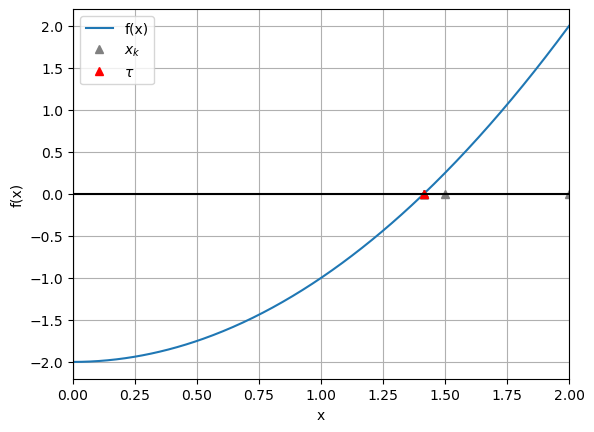

<IPython.core.display.Latex object>

 k      x_k     |f(x_k)|  |tau - x_k|
 0 2.000000 2.000000e+00 5.857864e-01
 1 1.500000 2.500000e-01 8.578644e-02
 2 1.416667 6.944444e-03 2.453104e-03
 3 1.414216 6.007305e-06 2.123901e-06
 4 1.414214 4.510614e-12 1.594946e-12
 5 1.414214 4.440892e-16 2.220446e-16
 6 1.414214 4.440892e-16 0.000000e+00


In [17]:
newton(f2,0,2,2)

#### Theorem 1.5.1 - The Newton Error Formula
if $f(\tau) = 0$ and $x_{k+1}=x_k-\frac{f(x_k)}{f'(x_k)}$, then there is a point $\eta_k$ between $\tau$ and $\_k$ such that:
$$\tau-x_{k+1}=-\frac{(t-x_k)^2}{2}\frac{f''(\eta_k)}{f'(x_k)} $$
  
For practical applications, use the above to bound the error at step $k+1$ when $\tau$ is unknown. With error at step k as $\varepsilon_k = |\tau-x_k|$, we can deduce:
$$\varepsilon_{k+1}\leq\varepsilon^2_k(\frac{\max\limits_{a\leq x\leq b}|f''(x)|}{2|f'(x_k)|})$$
Then, using that $\varepsilon\leq|b-a|$, use the above to bound $\varepsilon_1, \varepsilon_2,$ etc.

In [21]:
def newton(f, a, b, x0=None, tau=True, eps=10**(-16), K=None, prec=0.0001):

    if tau:
        true_soln = root_scalar(f, bracket=[a, b], xtol=1e-15).root

    if x0 == None:
        x_0 = np.random.uniform(a, b)
    else:
        x_0 = x0
        
    x_k_all = [x_0]

    if K != None:
        eps = 10**(-16)

    # method    
    x_k = x_0
    k = 1

    # error
    err_0 = abs(b-a)
    #err_0 = max(x_0 - a, b - x_0) #for tighter error bound, go from first x to nearest bound instead of full interval
    err_all = [err_0]
    err_k = err_0
    k = 1
    step = abs(b-a)/prec

    while True:
        # condition for Newton's method
        if deriv(f)(x_k) == 0:
            print("Error: Newton's Method not applicable where f'(x_k) = 0")
            break
        else:
            # check if current error is lower than the stopping point:
            if tau:
                # by true solution, if known
                if abs(true_soln - x_k) <= eps:
                    break
            else:
                # or by newton error formula
                if err_k <= eps:
                    break
            
            # method
            x_k1 = x_k - f(x_k)/deriv(f)(x_k)
            x_k_all.append(x_k1)

            # error formula
            err_k1 = (err_k**2)*(max([deriv(f,2)(x) for x in np.linspace(a, b, round(step))])/(2*abs(deriv(f)(x_k))))
            err_all.append(err_k1)

            # set up next step
            x_k = x_k1
            err_k = err_k1
            k += 1

    x = np.linspace(a, b, 401)
    plt.plot(x, f(x), label = '$f(x)$')
    plt.plot(x_k_all, [0]*(len(x_k_all)), "^", color = "gray", label = '$x_k$')
    if tau:
        plt.plot(true_soln, [0], "^", color = "r", label = '$\\tau$')

    plt.axhline(0, color='k', linewidth=1.5)  # x-axis
    plt.axvline(0, color='k', linewidth=1.5)  # y-axis
    plt.xlabel("x"), plt.ylabel("f(x)")
    plt.xlim(a,b)
    plt.grid(True)
    plt.show()

    k_all = range(k)
    fxk_all = [abs(f(xk)) for xk in x_k_all]
    if tau:
        err_bound = [abs(true_soln - xk) for xk in x_k_all]
        display(Latex(rf"$\tau = {true_soln:.6f}$"))
        df = pd.DataFrame(zip(k_all, x_k_all, fxk_all, err_bound), columns = ["k", "x_k", "|f(x_k)|", "|tau - x_k|"])
    else:
        #err_bound = [e if e < 1 else np.nan for e in err_all]
        err_bound = err_all
        display(Latex(rf"$\tau$ unknown. Newton Error Formula used."))
        df = pd.DataFrame(zip(k_all, x_k_all, fxk_all, err_bound), columns = ["k", "x_k", "|f(x_k)|", "Theoretical error bound"])

    print(df.to_string(index = False))

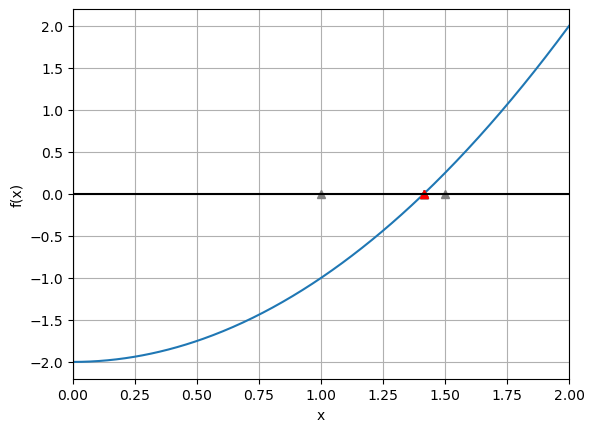

<IPython.core.display.Latex object>

 k      x_k     |f(x_k)|  |tau - x_k|
 0 1.000000 1.000000e+00 4.142136e-01
 1 1.500000 2.500000e-01 8.578644e-02
 2 1.416667 6.944444e-03 2.453104e-03
 3 1.414216 6.007305e-06 2.123901e-06
 4 1.414214 4.510614e-12 1.594946e-12
 5 1.414214 4.440892e-16 2.220446e-16
 6 1.414214 4.440892e-16 0.000000e+00


In [22]:
newton(f2, 0, 2, 1, tau=True)

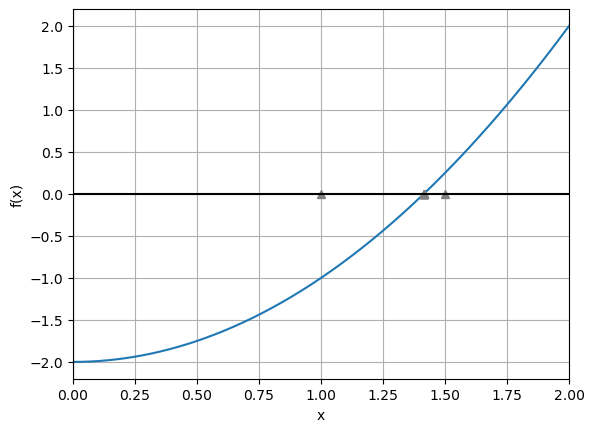

<IPython.core.display.Latex object>

 k      x_k     |f(x_k)|  Theoretical error bound
 0 1.000000 1.000000e+00             2.000000e+00
 1 1.500000 2.500000e-01             2.000000e+00
 2 1.416667 6.944444e-03             1.333333e+00
 3 1.414216 6.007305e-06             6.274510e-01
 4 1.414214 4.510614e-12             1.391919e-01
 5 1.414214 4.440892e-16             6.849879e-03
 6 1.414214 4.440892e-16             1.658902e-05
 7 1.414214 4.440892e-16             9.729639e-11
 8 1.414214 4.440892e-16             3.346944e-21


In [ ]:
newton(f2, 0, 2, 1, tau=False)

See also: Steffenson's Method.

### 1.6 Fixed Point Iteration
Choose a function $g$ such that, if $f(\tau)=0$, then $\tau$ is a fixed point of $g$.  
Choose $x_0$, and then iterate with $x_{k+1}=g(x_k)$, so that as $k\to\infty$, $x_k\to\tau$.
  
#### Theorem 1.6.1 - The Fixed Point Theorem
Suppose the function $g$ is continuous on $[a,b], and $a \le g(x) \le b$ for all $x\in[a,b]$. Then $g(x)$ has a *fixed point* in $[a,b]$.

#### Choosing g(x)
This method works under set conditions. It will only converge if $|g'(x)|<1$ for all $x$ near the fixed point (by Mean Value Theorem).   
$g(x)$ must map the interval $[a,b]$ back onto $[a,b]$  
  
**Definition: Fixed Point:**  
A function $g:\reals\to\reals$ is said to have a fixed point a t $x=\tau$ if $g(\tau)=\tau$.  
Therefore: $f(\tau) = 0 = g(\tau)-\tau$  
  
$\implies$ choose $g(x)$ such that $f(x) = g(x) - x$  
i.e. $g(x) = f(x)+x$  
  
**Definition: Contraction**  
Let $g$ be a continuous function defined on $[a,b]$. If there is a number $L\in(0,1)$ such that:
$$|g(\alpha)-g(\beta)|\leq L|\alpha-\beta|\text{    for all }\alpha, \beta\in[a,b]$$
then we say that $g$ is a **contraction** on $[a,b]$.  
  
Note:  $L\in(0,1)\implies 0 < L < 1$; in particular, strictly $L < 1$  
  
$L$ is called the contraction constant: $|g'(x)|\le L<1$ on the interval. $%note this is not from the notes$

#### Theorem 1.6.2 - Contraction Mapping Theorem
Suppose that the function $g$ is real-valued, defined, continuous and:  
&emsp;*(a)*&ensp;maps every point in $[a,b]$ to some point in [a,b], and  
&emsp;*(b)*&ensp;is a contraction on $[a,b]$,  
then   
&emsp;*(i)*&ensp;$g(x)$ has a fixed point $\tau\in[a,b]$, and  
&emsp;*(ii)*&ensp;the sequence $\{x_k\}^{\infty}_{k=0}$ defined by $x_0 \in [a,b]$ and $x_k=g(x_{k-1})$ for $k=1,2,...$ converges at least linearly to $\tau$. 
  
#### Number of Iterations
For a given accuracy, how many iterations are needed? E.g. for accuracy of $10^{-6}$, find $k$ such that $|x_k-\tau|\le 10^{-6}$. This has to be done *a posteriori*, empirically rather than deductively.  
  
The *a priori* error bound for FPI is $$ |\tau -x_k|\le \frac{L^k}{1-L}|x_1-x_0| $$  
  
Call the error bound $B$, where $B = \frac{L^k}{1-L}|x_1-x_0|$.  
For the error tolerance $\varepsilon$, we want  $|\tau -x_k| \le \varepsilon$, i.e. actual error at most the tolerance $\varepsilon$.  
Chaining the inequalities, we get $|\tau -x_k|\le B \le \varepsilon$, so solve:  
$$ \frac{L^k}{1-L}|x_1-x_0| \le \varepsilon$$
Multiply both sides by $(1-L)$ and divide by $|x_1-x_0|$
  
Log both sides. 
  
Because $0 < L < 1$, $\ln L$ is negative, so flip the inequality when dividing by $\ln L$, to get $k$:
$$ k \ge \frac{\ln(\frac{\varepsilon (1-L)}{|x_1-x_0|})}{\ln L} $$
Take the smallest integer $k$ satisfying the above inequality.
  


In [ ]:
#def fpi(f, a, b, x0, eps):
f = f2
a = 0
b = 2
x0 = 1
eps = 10**(-6)
#

x_0 = x0 #see if we need to specify x_0 every time

x_all = [x_0]

#define g
def g(x):
    return f(x) + x

# check g maps interval onto itself
g_int = [g(x) for x in np.linspace(a, b, 100)]
if max(g_int) > b or min(g_int) < a:
    print("Fatal error: cannot use FPI where g(x) does not map the interval onto itself")
else:
    # k iterations
    x_1 = g(x_0)
    x_all.append(x_1)
    L = max([abs(x) for x in g_int])
    k = round((np.log((eps*(1-L))/(abs(x_1 - x_0)))/np.log(L)))
    for i in range(k):
        